# Chapter 10 · 주문 취소 여부 분류 분석

- 이름: 서지민 (의예과, 2024-14010)
- GitHub ID: jasminmuze
- 작성일: 2026-11-12
- 저장소: https://github.com/jasminmuze/llm-data-analysis-study
- 분석 단위: 주문 1건

완료 주문과 취소 주문만 대상으로 취소 여부를 예측합니다. 예측 시점을 분명히 하고 주문·고객 식별자와 최종 주문 상태를 모델 입력에서 제외합니다. 정확도만 보지 않고 Validation에서 모델과 임계값을 고정한 뒤 Final Test의 Precision, Recall, F1, FP/FN으로 사용 가능성을 판단합니다.

## 분석 질문, 예측 시점, 데이터

**분석 질문:** 주문 정보가 확인된 시점에 취소될 주문을 어느 정도 식별할 수 있는가?

- 타깃: is_cancelled
- 0: completed, 1: cancelled
- refunded 및 기타 상태는 이진 분류에서 제외합니다.
- 예측 시점: 주문·고객·결제 정보와 장바구니가 확정된 뒤, 최종 주문 상태가 기록되기 전으로 가정합니다.
- 사용 feature: 나이, 장바구니 품목 수·수량·주문 금액, 주문 월·요일, 성별, 도시, 결제 수단
- 금지 정보: order_status, is_cancelled, 주문·고객·상품 ID, 취소 이후 생성 정보

수업 저장소의 [공통 Raw 데이터](https://github.com/GilbertMoon/llm-data-analysis-course/tree/main/data/raw)는 고객 150행, 상품 100행, 주문 300행, 주문 상세 764행입니다. 교육용 생성 데이터라 실제 고객·상점의 취소 행동을 대표하지 않습니다.

## 1. 프로젝트 루트와 실행 환경 설정

수업 공통 Raw 데이터를 사용합니다. Chapter05 오류 탐지용 전용 Raw는 사용하지 않습니다. 저장소 루트에서 아래 순서로 실행합니다.

    python -m pip install -r requirements.txt
    python scripts/prepare_ch10_data.py
    python scripts/run_classification_analysis.py

이 노트북은 같은 프로젝트 루트의 data/processed와 src/classification.py를 사용하며 전체 실행 결과는 reports/ 아래에 저장됩니다.

In [ ]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)


## 2. 전처리 데이터 확인과 불러오기

이 장에서는 `customers_clean.csv`, `orders_clean.csv`, `order_items_clean.csv`를 사용합니다.


In [ ]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        '전처리 파일이 없습니다: '
        + ', '.join(str(path) for path in missing_files)
        + '. 먼저 python scripts/prepare_ch10_data.py를 실행하세요.'
    )

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('customers:', customers.shape, customers.columns.tolist())
print('orders:', orders.shape, orders.columns.tolist())
print('order_items:', order_items.shape, order_items.columns.tolist())


## 3. 주문 상태와 타깃 범위 확인

이번 실습은 완료 주문과 취소 주문만 비교합니다.

- `completed` → 0
- `cancelled` → 1
- `refunded`와 기타 상태 → 학습 대상에서 제외


In [8]:
status_summary = (
    orders['order_status']
    .value_counts(dropna=False)
    .rename_axis('order_status')
    .reset_index(name='order_count')
)
status_summary


order_status,order_count
completed,184
cancelled,64
refunded,52


## 4. 분류 데이터와 병합 검증표 생성

공통 함수는 주문 특징 집계, 안전한 병합, 시간 순서 점검, 타깃 생성까지 수행합니다.


In [10]:
from src.classification import (
    build_classification_dataset,
    target_distribution,
)

(
    model_data,
    numeric_features,
    categorical_features,
    merge_checks,
    data_quality_checks,
) = build_classification_dataset(
    customers=customers,
    orders=orders,
    order_items=order_items,
)

target_dist = target_distribution(model_data)

print('모델링 데이터:', model_data.shape)
print('숫자형 feature:', numeric_features)
print('범주형 feature:', categorical_features)
display(target_dist)
display(merge_checks)
display(data_quality_checks)


모델링 데이터: (248, 16)
숫자형 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek']
범주형 feature: ['gender', 'city', 'payment_method']


is_cancelled,class_label,count,ratio
0,completed,184,0.7419
1,cancelled,64,0.2581


merge,before_rows,after_rows,row_count_preserved,unmatched_count,status
order_id → order_item_features,248,248,true,0,PASS
customer_id → customers,248,248,true,0,PASS


check_item,count
binary_target_rows,248
completed_rows,184
cancelled_rows,64
excluded_status_rows,52
line_total_mismatch,0
negative_days_since_signup,45
days_since_signup_feature_excluded,1
missing_order_item_features,0
missing_customer_match,0
status_scope:completed,184


### 데이터 품질 관찰: 가입일과 주문일의 순서

0·1 타깃 후보 248건 가운데 45건에서 고객 가입일이 주문일보다 늦었습니다. 이 값으로 계산한 days_since_signup은 의미가 없으므로 해당 선택형 feature만 제외하고 주문 행은 보존했습니다. data_quality_checks에 45건과 feature 제외 여부를 기록합니다. 주문 상세 계산 불일치, 주문·주문상세·고객 미매칭은 0건이었습니다. 임의로 날짜를 고치거나 잘못된 값을 0으로 채우지 않았습니다.

## 5. 데이터 누수 확인

`order_status`와 `is_cancelled`는 입력 feature에 포함되면 안 됩니다.


In [13]:
features = numeric_features + categorical_features
leakage_columns = {'order_status', 'is_cancelled'}
leakage_found = sorted(leakage_columns.intersection(features))

if leakage_found:
    raise ValueError(f'데이터 누수 위험 컬럼이 포함되었습니다: {leakage_found}')

print('사용 feature:', features)
print('데이터 누수 컬럼 없음')


사용 feature: age, item_count, total_quantity, order_amount, order_month, order_dayofweek, gender, city, payment_method
데이터 누수 컬럼 없음


## 6. train, validation, test 분리

모델과 임계값은 validation에서 선택하고, test는 최종 평가에 한 번만 사용합니다.


In [15]:
from src.classification import (
    split_train_validation_test,
    build_split_summary,
)

(
    X_train,
    X_valid,
    X_test,
    y_train,
    y_valid,
    y_test,
    features,
) = split_train_validation_test(
    model_data=model_data,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

split_summary = build_split_summary(y_train, y_valid, y_test)

print('X_train:', X_train.shape)
print('X_valid:', X_valid.shape)
print('X_test:', X_test.shape)
display(split_summary)


X_train: (148, 9)
X_valid: (50, 9)
X_test: (50, 9)


split,class_label,count,ratio
train,completed,110,0.7432
train,cancelled,38,0.2568
validation,completed,37,0.74
validation,cancelled,13,0.26
test,completed,37,0.74
test,cancelled,13,0.26


## 7. 기준 모델과 학습 모델 비교

가장 많은 클래스만 예측하는 Dummy 모델을 기준으로 Logistic Regression과 Random Forest의 validation 성능을 비교합니다.


In [17]:
from src.classification import train_and_compare_on_validation

(
    models,
    validation_comparison,
    validation_predictions,
    validation_probabilities,
) = train_and_compare_on_validation(
    X_train=X_train,
    X_valid=X_valid,
    y_train=y_train,
    y_valid=y_valid,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

validation_comparison


model,evaluation_split,accuracy,precision,recall,f1
Logistic Regression,validation,0.72,0.4666666666666667,0.5384615384615384,0.5
Random Forest,validation,0.68,0.3636363636363636,0.3076923076923077,0.3333333333333333
Dummy Most Frequent,validation,0.74,0,0,0


## 8. validation에서 모델과 임계값 선택

Dummy 모델은 기준선이므로 실제 선택 후보에서는 제외합니다. validation의 f1-score를 우선하고 recall과 precision을 함께 확인합니다.


In [19]:
from src.classification import threshold_metrics, choose_threshold, select_validation_model

selected_model_name = select_validation_model(validation_comparison)
selected_model = models[selected_model_name]
validation_proba = validation_probabilities[selected_model_name]

threshold_df = threshold_metrics(y_valid, validation_proba)
selected_threshold = choose_threshold(threshold_df)

print('선택 모델:', selected_model_name)
print('선택 임계값:', selected_threshold)
display(threshold_df.sort_values(['f1', 'recall'], ascending=False).head(10))

선택 모델: Logistic Regression
선택 임계값: 0.45


threshold,accuracy,precision,recall,f1
0.4,0.62,0.3846153846153846,0.7692307692307693,0.5128205128205128
0.45,0.7,0.45,0.6923076923076923,0.5454545454545454
0.5,0.72,0.4666666666666667,0.5384615384615384,0.5
0.55,0.76,0.5454545454545454,0.4615384615384615,0.5
0.6,0.78,0.6,0.4615384615384615,0.5217391304347826


## 9. test 데이터 최종 평가

이제 선택이 끝났으므로 test 데이터에서 최종 성능을 한 번 확인합니다.


In [21]:
from src.classification import (
    final_test_evaluation,
    confusion_matrix_dataframe,
    classification_report_dataframe,
)

y_pred_test, y_proba_test, test_metrics = final_test_evaluation(
    selected_model,
    X_test,
    y_test,
    threshold=selected_threshold,
)

confusion_df = confusion_matrix_dataframe(y_test, y_pred_test)
classification_report_df = classification_report_dataframe(y_test, y_pred_test)

display(test_metrics)
display(confusion_df)
display(classification_report_df)


evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
test,0.45,frozen_before_test,0.6,0.3157894736842105,0.4615384615384615,0.375


actual,pred_completed,pred_cancelled
actual_completed,24,13
actual_cancelled,7,6


label,precision,recall,f1-score,support
completed,0.7741935483870968,0.6486486486486487,0.7058823529411765,37
cancelled,0.3157894736842105,0.4615384615384615,0.375,13
accuracy,0.6,0.6,0.6,0.6
macro avg,0.5449915110356536,0.5550935550935552,0.5404411764705883,50
weighted avg,0.6550084889643464,0.6,0.6198529411764706,50


혼동행렬은 다음처럼 읽습니다.

| 구분 | 의미 |
|---|---|
| True Negative | 실제 완료 주문을 완료로 예측 |
| False Positive | 실제 완료 주문을 취소로 잘못 예측 |
| False Negative | 실제 취소 주문을 완료로 잘못 예측 |
| True Positive | 실제 취소 주문을 취소로 예측 |


## 10. 개인정보를 제외한 예측 결과 생성

고객명, 이메일, 주소 같은 불필요한 식별정보는 결과 파일에 저장하지 않습니다.


In [24]:
from src.classification import create_prediction_result

prediction_result = create_prediction_result(
    source_index=X_test.index,
    y_test=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=selected_model_name,
    threshold=selected_threshold,
)

prediction_result.head()


record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
test_0001,0,1,0.6835350157419511,Logistic Regression,0.45
test_0002,0,0,0.4094307469809694,Logistic Regression,0.45
test_0003,0,1,0.5125305689108172,Logistic Regression,0.45
test_0004,0,1,0.6022331996078735,Logistic Regression,0.45
test_0005,0,1,0.7463770890189995,Logistic Regression,0.45
test_0006,1,0,0.2228021510796796,Logistic Regression,0.45
test_0007,0,0,0.4195255844330535,Logistic Regression,0.45
test_0008,0,0,0.3981471028597033,Logistic Regression,0.45
test_0009,1,0,0.2957678817380834,Logistic Regression,0.45
test_0010,0,1,0.5230721290188192,Logistic Regression,0.45


## 11. LLM 코드 검토 체크리스트


In [26]:
from src.classification import build_classification_checklist

classification_checklist = build_classification_checklist()
classification_checklist


check_item,status
completed와 cancelled만 사용해 이진 타깃을 만들었는가?,□
refunded 등 다른 상태를 0 클래스에 섞지 않았는가?,□
예측 시점과 feature 가용성 가정을 설명할 수 있는가?,□
line_total = quantity × unit_price를 검증했는가?,□
병합에 validate를 사용하고 미매칭 0건을 확인했는가?,□
"order_status, target, ID, 사후 정보를 feature에서 제외했는가?",□
"train, validation, test를 분리했는가?",□
모델과 threshold는 validation에서 선택했는가?,□
모델과 threshold를 고정한 뒤 test를 한 번만 사용했는가?,□
Dummy 기준 모델과 비교했는가?,□


## 12. 전체 파이프라인 실행과 산출물 저장

위 과정을 한 번에 다시 실행해 CSV와 Markdown 보고서를 생성합니다.


In [28]:
from src.classification import run_classification_analysis

classification_result = run_classification_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    random_state=42,
)

print('선택 모델:', classification_result['selected_model_name'])
print('선택 임계값:', classification_result['selected_threshold'])
display(classification_result['test_metrics'])

for name, path in classification_result['output_paths'].items():
    print(name, path, 'OK' if path.exists() else 'MISSING')


선택 모델: Logistic Regression
선택 임계값: 0.45
생성한 Evidence: 14개 파일


evaluation_split,threshold,accuracy,precision,recall,f1
test,0.45,0.6,0.3157894736842105,0.4615384615384615,0.375


check,value,status
target_exactly_completed_cancelled,"[np.int64(0), np.int64(1)]",PASS
forbidden_feature_overlap,0,PASS
merge_rows_and_matches,True,PASS
all_splits_have_both_classes,True,PASS
model_selected_on_validation,True,PASS
threshold_selected_on_validation,True,PASS
public_prediction_identifier_columns,none,PASS


## 13. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 주문 취소 분류 코드를 검토해 주세요.

타깃 기준:
- completed=0
- cancelled=1
- refunded와 기타 상태는 제외

검토 항목:
1. order_status와 is_cancelled가 feature에서 제외되었는가?
2. 병합에 validate와 indicator가 사용되었는가?
3. train, validation, test가 분리되었는가?
4. 모델과 임계값은 validation에서 선택했는가?
5. test는 최종 평가에 한 번만 사용했는가?
6. Dummy 기준 모델보다 나은가?
7. accuracy, precision, recall, f1을 함께 확인했는가?
8. 예측 결과에 개인정보가 포함되지 않았는가?
9. 모델 결과를 취소 원인으로 단정하지 않았는가?

필수 수정과 권장 개선을 구분해 설명해 주세요.
```


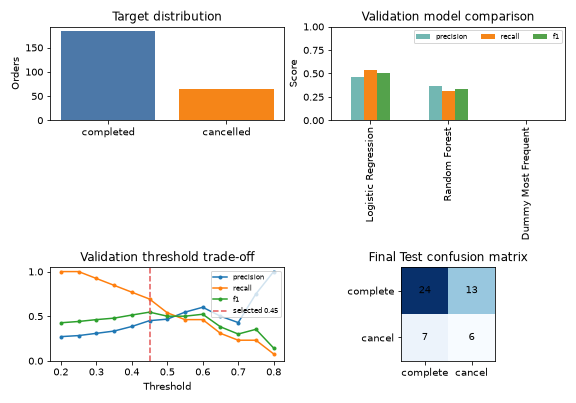

In [30]:
# 요약 그래프: 클래스 비율, Validation 비교, threshold trade-off, Final Test 혼동행렬
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(8, 5.6), dpi=72)
axes[0, 0].bar(target_dist['class_label'], target_dist['count'], color=['#4C78A8', '#F58518'])
axes[0, 0].set_title('Target distribution')
axes[0, 0].set_ylabel('Orders')

validation_comparison.set_index('model')[['precision', 'recall', 'f1']].plot(
    kind='bar', ax=axes[0, 1], color=['#72B7B2', '#F58518', '#54A24B']
)
axes[0, 1].set_title('Validation model comparison')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_xlabel('')
axes[0, 1].legend(fontsize=7, ncol=3)

for metric in ['precision', 'recall', 'f1']:
    axes[1, 0].plot(threshold_df['threshold'], threshold_df[metric], marker='.', label=metric)
axes[1, 0].axvline(selected_threshold, color='#E45756', linestyle='--', label=f'selected {selected_threshold:.2f}')
axes[1, 0].set_title('Validation threshold trade-off')
axes[1, 0].set_xlabel('Threshold')
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].legend(fontsize=7)

im = axes[1, 1].imshow(confusion_df.to_numpy(), cmap='Blues')
axes[1, 1].set_title('Final Test confusion matrix')
axes[1, 1].set_xticks([0, 1], ['complete', 'cancel'])
axes[1, 1].set_yticks([0, 1], ['complete', 'cancel'])
for (row, col), value in __import__('numpy').ndenumerate(confusion_df.to_numpy()):
    axes[1, 1].text(col, row, str(int(value)), ha='center', va='center')
fig.tight_layout()
display(fig)
plt.close(fig)

## 15. 결과와 해석

### 관찰된 결과

- 주문 원본 300건 중 completed 184건(74.2%), cancelled 64건(25.8%), refunded 52건(17.3%)이었습니다. 이진 모델링에는 완료·취소 248건만 사용했습니다.
- 층화 분할은 Train 148건, Validation 50건, Test 50건이며 세 분할 모두 두 클래스를 포함합니다.
- Validation 비교에서 Logistic Regression이 F1 0.500으로 Dummy Most Frequent(정확도 0.740, 취소 F1 0)와 Random Forest(F1 0.333)보다 취소 탐지 F1이 높아 선택됐습니다. Dummy의 정확도가 가장 높아 Accuracy 하나만 보면 오해할 수 있습니다.
- Validation에서 F1을 우선하는 기준으로 threshold 0.45를 선택했습니다. 이 지점의 Precision 0.450, Recall 0.692, F1 0.545입니다.
- 선택을 고정한 Final Test 결과는 Accuracy 0.600, Precision 0.316, Recall 0.462, F1 0.375입니다. 혼동행렬은 TN 24, FP 13, FN 7, TP 6이며 Validation보다 F1이 낮았습니다.

### FP/FN의 실제 의미와 한계

FP 13건은 완료 주문을 취소 위험으로 표시한 경우라면 불필요한 확인·연락이나 고객 불편을 만들 수 있습니다. FN 7건은 실제 취소를 놓쳐 취소 방지 대응 기회를 잃을 수 있습니다. 취소 방지 목적에서는 FN을 더 부담스럽게 볼 수 있지만, 실제 손실액·개입 성공률·연락 비용이 없어 오류 비용의 우열을 확정하지 않았습니다. 선택 threshold는 F1 기준의 균형점이지 검증된 사업 최적점이 아닙니다.

### 최종 판단: 추가 검증 후 사용 가능

이 결과는 교육용 탐색 참고로만 볼 수 있습니다. 248건의 작은 생성 데이터와 무작위 분할 결과라 실제 미래 주문에 일반화된다고 말할 수 없습니다. 운영 전에는 시간순 out-of-time 검증, 더 많은 실제 주문, 취소 예방 개입의 비용·효과 자료가 필요합니다. 상품·수량·주문 금액 feature는 예측 시점에 실제 확보된 장바구니 정보라는 가정을 확인해야 합니다.

## 16. LLM 사용과 코드 검증

생성형 AI를 사용해 과제 체크리스트, 누수 점검, 결과 해석 초안을 정리했습니다. 실제 실행에서 가입일이 주문일보다 늦은 사례 45건을 발견해 days_since_signup을 사용하지 않도록 수정했고 주문 행은 삭제하지 않았습니다. 파이프라인 실행 결과에서 FK 병합, Target 정의, feature 누수, 모든 split 내 두 클래스, Validation 기반 모델·threshold 선택, 공개 결과 식별자 제거가 모두 PASS였습니다. 자동 PASS는 운영 가능성을 보증하지 않으므로 테스트 성능과 데이터 한계를 근거로 추가 검증을 권고합니다.

## 17. 정리

이번 장에서는 완료 주문과 취소 주문을 명확하게 구분하고, 병합 검증, 데이터 누수 방지, train/validation/test 분리, 기준 모델 비교, validation 기반 모델·임계값 선택, 최종 test 평가를 수행했습니다.

다음 장에서는 LLM을 활용해 분석 질문과 프롬프트를 더 구체적으로 만드는 방법으로 이어집니다.
